In [1]:
import os
import sys
import glob
import numpy as np
import skimage.io, skimage.morphology
import matplotlib.pyplot as plt
import numba
import scipy.ndimage 

import csv
from multiprocessing import Manager, Lock
from concurrent.futures import ProcessPoolExecutor, as_completed

In [2]:
class Plate:

    def __init__(self, _name):
        self.name = _name
    
    def set_file_lists(self, _file_lists):
        self.fch1 = _file_lists[0]
        self.fch2 = _file_lists[1]
        self.fch3 = _file_lists[2]
        self.fch4 = _file_lists[3]

        assert(len(self.fch1) == len(self.fch2))
        assert(len(self.fch1) == len(self.fch3))
        assert(len(self.fch1) == len(self.fch4))
        self.num_images = len(self.fch1)
        

In [3]:
# Find all image pairs

BASE_DIR = "/media/user/SSD2/Athena/Hao_PRPC/PRPC/2025-07-09_60x_3plates/20250613 Lzso50screen/60x"
NUM_PLATES = 3

plates = []  # holds `plate` objects

for i in range(NUM_PLATES):

    plate_name = "plate%d" % (i+1)
    plate = Plate(plate_name)

    ch1_list = sorted(glob.glob("%s/%s_IJsplit/CH1/probabilities/*_Probabilities.tif" % (BASE_DIR, plate_name)))
    ch2_list = sorted(glob.glob("%s/%s_IJsplit/CH2/probabilities_cells/*_Probabilities.tif" % (BASE_DIR, plate_name)))
    ch3_list = sorted(glob.glob("%s/%s_IJsplit/CH3/probabilities/*_Probabilities.tif" % (BASE_DIR, plate_name)))
    ch4_list = sorted(glob.glob("%s/%s_IJsplit/CH4/probabilities/*_Probabilities.tif" % (BASE_DIR, plate_name)))

    plate.set_file_lists([ch1_list, ch2_list, ch3_list, ch4_list])

    plates.append(plate)
    

In [4]:
def get_well_field(paths):
    well, field = paths[0].split("POM2_")[1].split("_")[0].split("-")
    return well, field


def pmap_to_mask(x):
    mask = np.zeros(x.shape, dtype=np.int32)
    mask[x>0.5] = 1
    return mask


def remove_small_holes(mask, area_threshold):
    mask = skimage.morphology.remove_small_holes(mask, area_threshold=area_threshold).astype(np.int32)
    return mask


def remove_small_objects(mask, min_size):
    mask = skimage.morphology.remove_small_objects(ar=mask>0, min_size=min_size, connectivity=2).astype(np.int32) # If ar is bool, the image is first labeled
    return mask



# RDF

@numba.jit(nopython=True, parallel=False, fastmath=True)  # race condition with parallel=True
def get_rdf(Nbins, lyso, dist):
    nx,ny = lyso.shape
    dx = 2  # size of each bin in pixels
    L = Nbins * dx  # max number of pixels away from nucleus edge
    rdf = np.zeros(Nbins)
    for i in numba.prange(nx):
        for j in numba.prange(ny):
            q = int(dist[i,j] // dx)
            if q*dx < L:
                if lyso[i,j]>0:
                    rdf[q] += 1
    return rdf


def compute_rdf(Nbins, mask_nuc, mask_cel, mask_lys, debug=False):
    # distance of lysosomes to nearest nucleus
    distance_to_nuclei = scipy.ndimage.distance_transform_edt(mask_nuc==0)
    distance_to_nuclei[mask_cel==0] = 0
    if debug:
        print("distance_to_nuclei dtype:", distance_to_nuclei.dtype)
        plt.imshow(distance_to_nuclei)
        plt.colorbar()
        plt.show()

    # rdf of lysosomes in cells
    rdf = get_rdf(Nbins, mask_lys, distance_to_nuclei)
    if debug:
        plt.plot(np.arange(Nbins), rdf)
        plt.xlabel("number of bins from nearest nucleus")
        plt.ylabel("total lysosome area in pixels")
        plt.show()
    return rdf



In [5]:
def process_image_pair(paths, debug=False):

    if debug:
        for p in paths:
            print(os.path.basename(p))

    fnuc = paths[0]
    fcel = paths[1]
    flys = paths[2]
    fprp = paths[3]

    # load image files
    img_nuc = skimage.io.imread(fnuc, plugin='tifffile').astype(float)  # probability map from ilastik
    img_cel = skimage.io.imread(fcel, plugin='tifffile').astype(float)  # probability map from ilastik
    img_lys = skimage.io.imread(flys, plugin='tifffile').astype(float)  # probability map from ilastik
    img_prp = skimage.io.imread(fprp, plugin='tifffile').astype(float)  # probability map from ilastik

    # convert probability map to mask
    mask_nuc = pmap_to_mask(img_nuc)
    mask_cel = pmap_to_mask(img_cel)
    mask_lys = pmap_to_mask(img_lys)
    mask_prp = pmap_to_mask(img_prp)

    # remove small holes from nuclei and cell masks
    mask_nuc = remove_small_holes(mask_nuc, area_threshold=400)
    mask_cel = remove_small_holes(mask_cel, area_threshold=11000)

    # remove small disconnected artifacts in nucleus and cell masks
    mask_nuc = remove_small_objects(mask_nuc, min_size=1000)
    mask_cel = remove_small_objects(mask_cel, min_size=5000)
    if debug:
        print("dtypes after remove_small_objects:")
        print(mask_nuc.dtype)
        print(mask_cel.dtype)
        print("")

    # add nuclei in cell mask, just in case they were missing
    mask_cel[mask_nuc==1] = 1

    # remove signal outside cells
    mask_nuc[mask_cel==0] = 0
    mask_lys[mask_cel==0] = 0
    mask_prp[mask_cel==0] = 0

    if debug:
        fig = plt.figure(figsize=(20,20))
        plt.subplot(1,5,1)
        plt.imshow(mask_nuc)
        plt.subplot(1,5,2)
        plt.imshow(mask_cel)
        plt.subplot(1,5,3)
        plt.imshow(mask_lys)
        plt.subplot(1,5,4)
        plt.imshow(mask_prp)
        plt.subplot(1,5,5)
        plt.imshow(img_cel, cmap="gray")
        plt.show()
        print(mask_nuc.dtype)
        print(mask_cel.dtype)
        print(mask_lys.dtype)
        print(mask_prp.dtype)

    # Compute total area per structure
    area_nuc = np.sum(mask_nuc)
    area_cel = np.sum(mask_cel)
    area_lys = np.sum(mask_lys)
    area_prp = np.sum(mask_prp)

    if debug:
        well, field = get_well_field(paths)
        print("well", well)
        print("field", field)
        print("area_nuc", area_nuc, area_nuc==np.sum(mask_nuc>0), float(area_nuc)/(mask_nuc.shape[0]*mask_nuc.shape[1]))
        print("area_cel", area_cel, area_cel==np.sum(mask_cel>0), float(area_cel)/(mask_cel.shape[0]*mask_cel.shape[1]))
        print("area_lys", area_lys, area_lys==np.sum(mask_lys>0), float(area_lys)/(mask_lys.shape[0]*mask_lys.shape[1]))
        print("area_prp", area_prp, area_prp==np.sum(mask_prp>0), float(area_prp)/(mask_prp.shape[0]*mask_prp.shape[1]))


    # Compute distribution of prpc inside cells
    # ALL STRUCTURES TOGETHER
    # map of structures
    # 0: empty
    # 1: nucleus
    # 2: cytoplasm
    # 3: lysosome
    structures_map = np.zeros(mask_nuc.shape, dtype=np.int32)
    structures_map[mask_cel==1] = 2  # largest areas, cover all other structures
    structures_map[mask_nuc==1] = 1
    structures_map[mask_lys==1] = 3
    structures_map[mask_cel==0] = 0

    if debug:
        plt.imshow(structures_map)
        plt.show()

    total_prpc_nucleus   = np.sum( (mask_prp==1) * (structures_map==1) )
    total_prpc_cell = np.sum( (mask_prp==1) * (structures_map==2) )
    total_prpc_lysosome  = np.sum( (mask_prp==1) * (structures_map==3) )

    total_prpc = total_prpc_nucleus + total_prpc_lysosome + total_prpc_cell
    sumPrPc = np.sum(mask_prp)
    assert(total_prpc == sumPrPc)


    # Compute rdf of lysosomes from nearest nucleus
    NBINS = 150
    if area_nuc>0 and area_lys>0:
        rdf = compute_rdf(NBINS, mask_nuc, mask_cel, mask_lys, debug)
    else:
        rdf = np.zeros(NBINS)

    return area_nuc, area_cel, area_lys, area_prp, total_prpc_nucleus, total_prpc_cell, total_prpc_lysosome, rdf


    

20250614_60x_4CLyso_405DAPI_488CellMask_561LAMP1_647POM2_B10-10_1215CH1_Probabilities.tif
20250614_60x_4CLyso_405DAPI_488CellMask_561LAMP1_647POM2_B10-10_1215CH2_Probabilities.tif
20250614_60x_4CLyso_405DAPI_488CellMask_561LAMP1_647POM2_B10-10_1215CH3_Probabilities.tif
20250614_60x_4CLyso_405DAPI_488CellMask_561LAMP1_647POM2_B10-10_1215CH4_Probabilities.tif
dtypes after remove_small_objects:
int32
int32



/tmp/ipykernel_2183329/571376397.py:13: UserWarning: Any labeled images will be returned as a boolean array. Did you mean to use a boolean array?
  mask = skimage.morphology.remove_small_holes(mask, area_threshold=area_threshold).astype(np.int32)


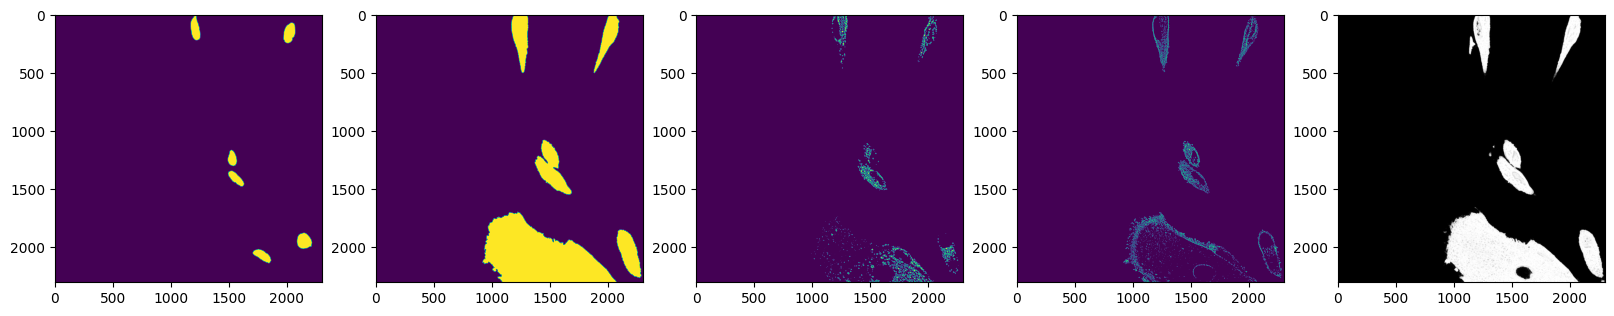

int32
int32
int32
int32
well B10
field 10
area_nuc 66403 True 0.012509004569347993
area_cel 615687 True 0.1159831859447338
area_lys 51404 True 0.009683491271219136
area_prp 56066 True 0.010561719352816358


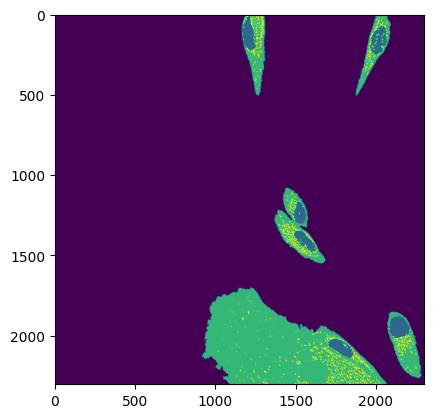

distance_to_nuclei dtype: float64


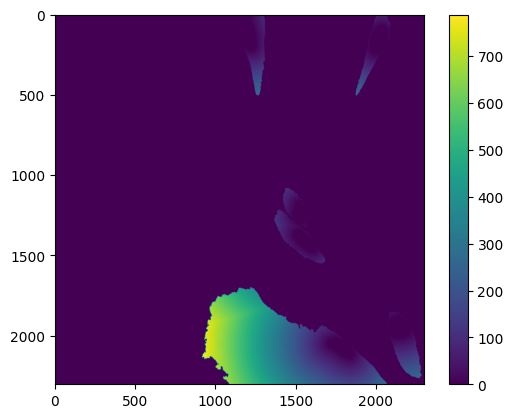

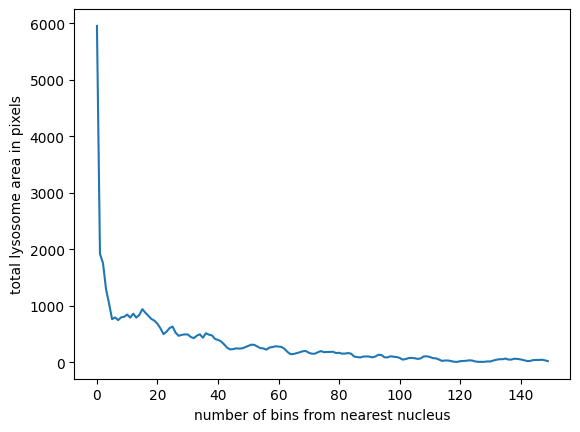

Check completed!


SystemExit: 

/home/user/.local/anaconda3/envs/HCS-AggreQuant/lib/python3.9/site-packages/IPython/core/interactiveshell.py:3558: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [6]:
# Loop over plates and images - SINGLE PROCESS - TESTING

for plate in plates:
    for paths in zip(plate.fch1, plate.fch2, plate.fch3, plate.fch4):
        area_nuc, area_cel, area_lys, area_prp, total_prpc_nucleus, total_prpc_cell, total_prpc_lysosome, rdf = process_image_pair(paths, debug=True)

        print("Check completed!")
        sys.exit()


In [ ]:
assert(0)

In [7]:
def process_images_multi(x, shared_list, lock):

    plate_name = x[0]
    paths = x[1]

    area_nuc, area_cel, area_lys, area_prp, total_prpc_nucleus, total_prpc_cell, total_prpc_lysosome, rdf = process_image_pair(paths)

    # get row, column from file name
    well, field = get_well_field(paths)
    row = well[0]
    col = int(well[1::])

    result = {
        "Plate": plate_name,
        "File": os.path.basename(paths[0]),
        "Well": well,
        "Row": row,
        "Column": col,
        "Field": field,
        "AreaNuclei": area_nuc,
        "AreaCells": area_cel,
        "AreaLyso": area_lys,
        "AreaPrPC": area_prp,
        "PrPc_in_DAPI": total_prpc_nucleus,
        "PrPc_in_Cell": total_prpc_cell,
        # "PrPc_in_CellEdge": total_prpc_celledge,  # 2025-08-21: Not possible, cell boarders are not distinguishable
        "PrPc_in_Lysosome": total_prpc_lysosome,
        "LysosomeRDF": ",".join(map(str,rdf))
    }

    with lock:
        shared_list.append(result)
    

In [8]:
# Loop over plates and images - MULTI PROCESSING

max_workers = 64
output_file_prefix = "output_2025-08-21_60x"


for plate in plates:
    plate_name = plate.name
    print("PROCESSING PLATE:", plate_name)

    Nfiles = plate.num_images

    output_file = "%s_%s.csv" % (output_file_prefix, plate_name)

    with Manager() as manager:
        shared_list = manager.list()
        lock = manager.Lock()

        with ProcessPoolExecutor(max_workers=max_workers) as executor:
            futures = [
                executor.submit(process_images_multi, [plate_name, paths], shared_list, lock)
                for paths in zip(plate.fch1, plate.fch2, plate.fch3, plate.fch4)
            ]
            for i,future in enumerate(as_completed(futures), 1):
                future.result()
                if i%10==0 or i==Nfiles:
                    print(f"Processed {i}/{Nfiles} images")

        header = ["Plate", "File", "Well", "Row", "Column", "Field",
                    "AreaNuclei", "AreaCells", "AreaLyso", "AreaPrPC", 
                    "PrPc_in_DAPI", "PrPc_in_Cell", "PrPc_in_Lysosome",
                    "LysosomeRDF"]

        with open(output_file, 'w', newline='\n') as f:
            writer = csv.DictWriter(f, fieldnames=header)
            writer.writeheader()
            for row in shared_list:
                writer.writerow(row)

PROCESSING PLATE: plate1


/tmp/ipykernel_2183329/571376397.py:13: UserWarning: Any labeled images will be returned as a boolean array. Did you mean to use a boolean array?
  mask = skimage.morphology.remove_small_holes(mask, area_threshold=area_threshold).astype(np.int32)
/tmp/ipykernel_2183329/571376397.py:13: UserWarning: Any labeled images will be returned as a boolean array. Did you mean to use a boolean array?
  mask = skimage.morphology.remove_small_holes(mask, area_threshold=area_threshold).astype(np.int32)
/tmp/ipykernel_2183329/571376397.py:13: UserWarning: Any labeled images will be returned as a boolean array. Did you mean to use a boolean array?
  mask = skimage.morphology.remove_small_holes(mask, area_threshold=area_threshold).astype(np.int32)
/tmp/ipykernel_2183329/571376397.py:13: UserWarning: Any labeled images will be returned as a boolean array. Did you mean to use a boolean array?
  mask = skimage.morphology.remove_small_holes(mask, area_threshold=area_threshold).astype(np.int32)
/tmp/ipykern

Processed 10/865 images
Processed 20/865 images
Processed 30/865 images
Processed 40/865 images
Processed 50/865 images
Processed 60/865 images
Processed 70/865 images
Processed 80/865 images
Processed 90/865 images
Processed 100/865 images
Processed 110/865 images
Processed 120/865 images
Processed 130/865 images
Processed 140/865 images
Processed 150/865 images
Processed 160/865 images
Processed 170/865 images
Processed 180/865 images
Processed 190/865 images
Processed 200/865 images
Processed 210/865 images
Processed 220/865 images
Processed 230/865 images
Processed 240/865 images
Processed 250/865 images
Processed 260/865 images
Processed 270/865 images
Processed 280/865 images
Processed 290/865 images
Processed 300/865 images
Processed 310/865 images
Processed 320/865 images
Processed 330/865 images
Processed 340/865 images
Processed 350/865 images
Processed 360/865 images
Processed 370/865 images
Processed 380/865 images
Processed 390/865 images
Processed 400/865 images
Processed

/tmp/ipykernel_2183329/571376397.py:13: UserWarning: Any labeled images will be returned as a boolean array. Did you mean to use a boolean array?
  mask = skimage.morphology.remove_small_holes(mask, area_threshold=area_threshold).astype(np.int32)
/tmp/ipykernel_2183329/571376397.py:13: UserWarning: Any labeled images will be returned as a boolean array. Did you mean to use a boolean array?
  mask = skimage.morphology.remove_small_holes(mask, area_threshold=area_threshold).astype(np.int32)
/tmp/ipykernel_2183329/571376397.py:13: UserWarning: Any labeled images will be returned as a boolean array. Did you mean to use a boolean array?
  mask = skimage.morphology.remove_small_holes(mask, area_threshold=area_threshold).astype(np.int32)
/tmp/ipykernel_2183329/571376397.py:13: UserWarning: Any labeled images will be returned as a boolean array. Did you mean to use a boolean array?
  mask = skimage.morphology.remove_small_holes(mask, area_threshold=area_threshold).astype(np.int32)
/tmp/ipykern

Processed 10/871 images
Processed 20/871 images
Processed 30/871 images
Processed 40/871 images
Processed 50/871 images
Processed 60/871 images
Processed 70/871 images
Processed 80/871 images
Processed 90/871 images
Processed 100/871 images
Processed 110/871 images
Processed 120/871 images
Processed 130/871 images
Processed 140/871 images
Processed 150/871 images
Processed 160/871 images
Processed 170/871 images
Processed 180/871 images
Processed 190/871 images
Processed 200/871 images
Processed 210/871 images
Processed 220/871 images
Processed 230/871 images
Processed 240/871 images
Processed 250/871 images
Processed 260/871 images
Processed 270/871 images
Processed 280/871 images
Processed 290/871 images
Processed 300/871 images
Processed 310/871 images
Processed 320/871 images
Processed 330/871 images
Processed 340/871 images
Processed 350/871 images
Processed 360/871 images
Processed 370/871 images
Processed 380/871 images
Processed 390/871 images
Processed 400/871 images
Processed

/tmp/ipykernel_2183329/571376397.py:13: UserWarning: Any labeled images will be returned as a boolean array. Did you mean to use a boolean array?
  mask = skimage.morphology.remove_small_holes(mask, area_threshold=area_threshold).astype(np.int32)
/tmp/ipykernel_2183329/571376397.py:13: UserWarning: Any labeled images will be returned as a boolean array. Did you mean to use a boolean array?
  mask = skimage.morphology.remove_small_holes(mask, area_threshold=area_threshold).astype(np.int32)
/tmp/ipykernel_2183329/571376397.py:13: UserWarning: Any labeled images will be returned as a boolean array. Did you mean to use a boolean array?
  mask = skimage.morphology.remove_small_holes(mask, area_threshold=area_threshold).astype(np.int32)
/tmp/ipykernel_2183329/571376397.py:13: UserWarning: Any labeled images will be returned as a boolean array. Did you mean to use a boolean array?
  mask = skimage.morphology.remove_small_holes(mask, area_threshold=area_threshold).astype(np.int32)
/tmp/ipykern

Processed 10/865 images
Processed 20/865 images
Processed 30/865 images
Processed 40/865 images
Processed 50/865 images
Processed 60/865 images
Processed 70/865 images
Processed 80/865 images
Processed 90/865 images
Processed 100/865 images
Processed 110/865 images
Processed 120/865 images
Processed 130/865 images
Processed 140/865 images
Processed 150/865 images
Processed 160/865 images
Processed 170/865 images
Processed 180/865 images
Processed 190/865 images
Processed 200/865 images
Processed 210/865 images
Processed 220/865 images
Processed 230/865 images
Processed 240/865 images
Processed 250/865 images
Processed 260/865 images
Processed 270/865 images
Processed 280/865 images
Processed 290/865 images
Processed 300/865 images
Processed 310/865 images
Processed 320/865 images
Processed 330/865 images
Processed 340/865 images
Processed 350/865 images
Processed 360/865 images
Processed 370/865 images
Processed 380/865 images
Processed 390/865 images
Processed 400/865 images
Processed